# Réplica de ViGeo-Fuse (He et al., 2026) – Fusión CNN + Random Forest geoespacial

**Paper:** He, Y. et al. (2026). *ViGeo-Fuse: A multimodal framework integrating computer vision and geospatial ML for post-earthquake building damage classification.* Developments in the Built Environment, 27, 101001.

**Qué replica este notebook** (con los datos públicos del repositorio `imi23333/damage-detection`):
1. **Modelo visual (CNN VGG16):** se usan las probabilidades que los autores ya calcularon (las fotos de Jishishan no son públicas).
2. **Modelo geoespacial (Random Forest):** se entrena desde cero con variables de amenaza y terreno.
3. **Fusión ViGeo-Fuse:** promedio ponderado de ambas probabilidades; el peso se elige en *validación* y se evalúa en *prueba*.
4. **Mapa de daño** con las predicciones.

Clases de daño: **0 = sin daño, 1 = leve, 2 = severo, 3 = total**.

👉 Ejecuta las celdas **en orden** (Entorno de ejecución → Ejecutar todas, o `Shift + Enter` celda por celda).

## Paso 1 · Instalar librerías

In [ ]:
!pip install -q imbalanced-learn folium openpyxl

## Paso 2 · Descargar los datos del repositorio de los autores

In [ ]:
!git clone -q https://github.com/imi23333/damage-detection.git
!ls damage-detection/data/pa5

test_multi.xlsx   val_multi.xlsx  多源数据融2.ipynb
train_multi.xlsx  其他数据源图像


## Paso 3 · Cargar los datos

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, cohen_kappa_score,
                             classification_report, confusion_matrix)
from imblearn.over_sampling import SMOTE

SEED = 2024
RUTA = 'damage-detection/data/pa5/'
train = pd.read_excel(RUTA + 'train_multi.xlsx')
val   = pd.read_excel(RUTA + 'val_multi.xlsx')
test  = pd.read_excel(RUTA + 'test_multi.xlsx')

# En el archivo de prueba las columnas de probabilidad tienen otro nombre: se uniformizan
test = test.rename(columns={'Probabilit': 'Probability_Class0', 'Probabil_1': 'Probability_Class1',
                            'Probabil_2': 'Probability_Class2', 'Probabil_3': 'Probability_Class3'})

print('Entrenamiento:', train.shape, '| Validación:', val.shape, '| Prueba:', test.shape)
train.head()

Entrenamiento: (5475, 34) | Validación: (683, 33) | Prueba: (702, 29)


,Image_Path,Label,Probability_Class0,Probability_Class1,Probability_Class2,Probability_Class3,Vulnerable,Vulnerab_1,Vulnerab_2,Vulnerab_3,...,Kriging_Vs30,Kriging_PGV_Z,Kriging_PGV_N,Kriging_PGV_E,Kriging_PGA_Z,Kriging_PGA_N,Kriging_PGA_E,psa0p3,PGV,PGA
0,D:\python\project\model\02-classification\data...,2,0.000130,0.002152,0.997074,0.000644,2,2,6,0,...,850.581421,18.515697,29.711401,33.567989,435.952240,518.622986,570.367065,0.42,14,0.24
1,D:\python\project\model\02-classification\data...,1,0.000039,0.886237,0.113689,0.000035,1,1,3,0,...,1094.902710,19.251350,25.876764,40.205521,562.495544,680.291260,778.995239,0.36,10,0.20
2,D:\python\project\model\02-classification\data...,0,0.498264,0.495281,0.006273,0.000182,1,1,2,0,...,714.898926,6.512402,14.345038,15.431259,318.470245,342.827057,428.702240,0.38,12,0.18
3,D:\python\project\model\02-classification\data...,2,0.000035,0.044886,0.940862,0.014218,1,3,2,0,...,1123.267090,27.800671,31.897865,46.307709,557.271729,618.730286,827.830994,0.54,18,0.24
4,D:\python\project\model\02-classification\data...,2,0.000272,0.006596,0.992982,0.000151,1,1,2,0,...,998.158813,6.632848,19.971960,25.623568,408.356659,455.127991,579.626343,0.40,12,0.20


## Paso 4 · Explorar los datos
Fíjate en el **desbalance de clases**: hay muchos más edificios con daño leve que con daño total.

,Entrenamiento,Validación,Prueba
Sin daño,568,68,60
Leve,2811,352,355
Severo,1889,234,259
Total,207,29,28


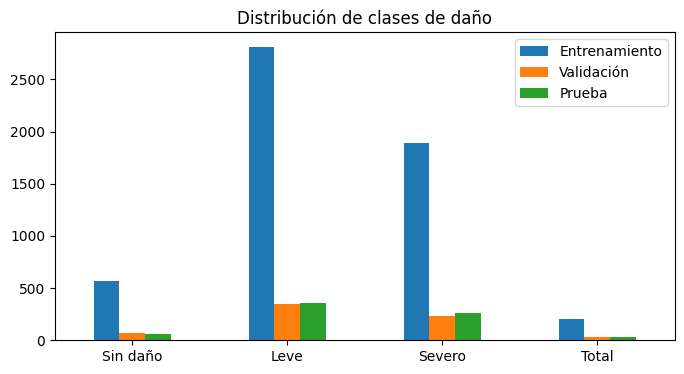

In [ ]:
NOMBRES = ['Sin daño', 'Leve', 'Severo', 'Total']
dist = pd.DataFrame({
    'Entrenamiento': train['Label'].value_counts().sort_index(),
    'Validación':    val['Label'].value_counts().sort_index(),
    'Prueba':        test['Label'].value_counts().sort_index()})
dist.index = NOMBRES
display(dist)
dist.plot(kind='bar', figsize=(8,4), title='Distribución de clases de daño'); plt.xticks(rotation=0); plt.show()

## Paso 5 · Definir las variables geoespaciales (conocimiento previo)
Son las variables que usan los autores en su notebook:

| Columna | Significado |
|---|---|
| `zhenzhong` | Distancia al epicentro (m) |
| `duanliedai` | Distancia a la zona de falla (m) |
| `liedu` | Intensidad sísmica (categórica) |
| `DEM` | Elevación (m) |
| `Slope` | Pendiente |
| `Aspect` | Orientación de la ladera |
| `qifudu` | Relieve del terreno |
| `NDVI` | Índice de vegetación |

In [ ]:
NUM = ['zhenzhong', 'duanliedai', 'DEM', 'Slope', 'Aspect', 'qifudu', 'NDVI']
CAT = ['liedu']
PROB = ['Probability_Class0', 'Probability_Class1', 'Probability_Class2', 'Probability_Class3']

print('Valores faltantes en entrenamiento:')
print(train[NUM + CAT].isnull().sum())

Valores faltantes en entrenamiento:
zhenzhong     0
duanliedai    0
DEM           0
Slope         0
Aspect        0
qifudu        0
NDVI          0
liedu         0
dtype: int64


## Paso 6 · Modelo 1: CNN (solo imagen)
Usamos las probabilidades de la VGG16 que vienen en los archivos. La clase predicha es la de mayor probabilidad.

              precision    recall  f1-score   support

    Sin daño      0.710     0.733     0.721        60
        Leve      0.790     0.848     0.818       355
      Severo      0.808     0.730     0.767       259
       Total      0.880     0.786     0.830        28

    accuracy                          0.792       702
   macro avg      0.797     0.774     0.784       702
weighted avg      0.793     0.792     0.791       702



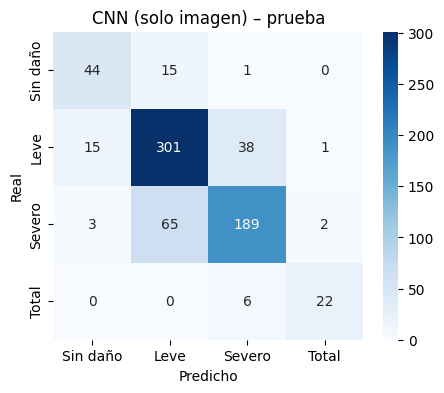

In [ ]:
def evaluar(y_real, y_pred, nombre):
    return {'Modelo': nombre,
            'Exactitud (OA)': accuracy_score(y_real, y_pred),
            'F1 macro': f1_score(y_real, y_pred, average='macro'),
            'F1 ponderado': f1_score(y_real, y_pred, average='weighted'),
            'Kappa': cohen_kappa_score(y_real, y_pred)}

def matriz(y_real, y_pred, titulo):
    cm = confusion_matrix(y_real, y_pred, labels=[0,1,2,3])
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=NOMBRES, yticklabels=NOMBRES)
    plt.xlabel('Predicho'); plt.ylabel('Real'); plt.title(titulo); plt.show()

p_cnn_val  = val[PROB].values
p_cnn_test = test[PROB].values
pred_cnn = p_cnn_test.argmax(axis=1)

print(classification_report(test['Label'], pred_cnn, target_names=NOMBRES, digits=3))
matriz(test['Label'], pred_cnn, 'CNN (solo imagen) – prueba')

## Paso 7 · Modelo 2: Random Forest (solo datos geoespaciales)
- Se normalizan las variables numéricas y se codifica la intensidad (one-hot). **El preprocesamiento se ajusta solo con entrenamiento** para evitar fuga de datos.
- Se aplica **SMOTE** para balancear las clases, como en el código original.
- Random Forest con 70 árboles (`random_state=2024`), igual que los autores.

Antes de SMOTE: [ 568 2811 1889  207] | Después: [2811 2811 2811 2811]
              precision    recall  f1-score   support

    Sin daño      0.574     0.583     0.579        60
        Leve      0.691     0.718     0.704       355
      Severo      0.625     0.579     0.601       259
       Total      0.469     0.536     0.500        28

    accuracy                          0.648       702
   macro avg      0.590     0.604     0.596       702
weighted avg      0.648     0.648     0.647       702



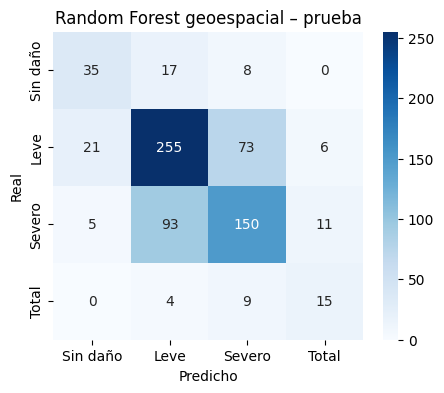

In [ ]:
prepro = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='mean')), ('esc', StandardScaler())]), NUM),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('ohe', OneHotEncoder(handle_unknown='ignore'))]), CAT)])

X_train = prepro.fit_transform(train[NUM + CAT])
X_val   = prepro.transform(val[NUM + CAT])
X_test  = prepro.transform(test[NUM + CAT])
y_train, y_val, y_test = train['Label'], val['Label'], test['Label']

X_bal, y_bal = SMOTE(random_state=42).fit_resample(X_train, y_train)
print('Antes de SMOTE:', np.bincount(y_train), '| Después:', np.bincount(y_bal))

rf = RandomForestClassifier(n_estimators=70, random_state=SEED, n_jobs=-1)
rf.fit(X_bal, y_bal)

p_rf_val  = rf.predict_proba(X_val)
p_rf_test = rf.predict_proba(X_test)
pred_rf = p_rf_test.argmax(axis=1)

print(classification_report(y_test, pred_rf, target_names=NOMBRES, digits=3))
matriz(y_test, pred_rf, 'Random Forest geoespacial – prueba')

### Importancia de las variables geoespaciales

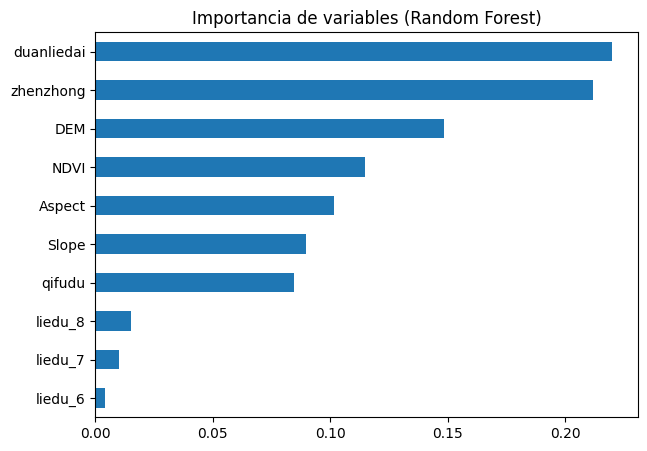

In [ ]:
nombres_var = NUM + list(prepro.named_transformers_['cat'].named_steps['ohe'].get_feature_names_out(CAT))
imp = pd.Series(rf.feature_importances_, index=nombres_var).sort_values()
imp.plot(kind='barh', figsize=(7,5), title='Importancia de variables (Random Forest)'); plt.show()

## Paso 8 · Fusión ViGeo-Fuse
Probabilidad final = **w × P(Random Forest) + (1 − w) × P(CNN)**

El peso `w` se busca en el conjunto de **validación** y luego se aplica una sola vez al de **prueba** (así el resultado es honesto).
> Nota: en el notebook original los autores buscaron el peso directamente sobre los datos que evaluaban; aquí se corrige eso.

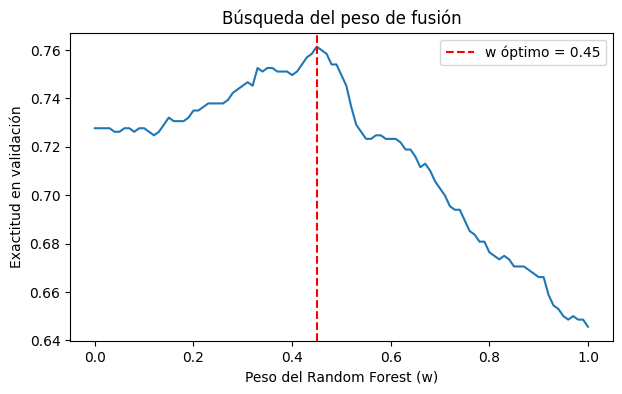

Peso óptimo del Random Forest: 0.45


In [ ]:
pesos = np.round(np.arange(0, 1.0001, 0.01), 2)
acc_val = [accuracy_score(y_val, (w*p_rf_val + (1-w)*p_cnn_val).argmax(1)) for w in pesos]
w_opt = pesos[int(np.argmax(acc_val))]

plt.figure(figsize=(7,4))
plt.plot(pesos, acc_val); plt.axvline(w_opt, ls='--', c='red', label=f'w óptimo = {w_opt}')
plt.xlabel('Peso del Random Forest (w)'); plt.ylabel('Exactitud en validación')
plt.title('Búsqueda del peso de fusión'); plt.legend(); plt.show()
print('Peso óptimo del Random Forest:', w_opt)

              precision    recall  f1-score   support

    Sin daño      0.796     0.717     0.754        60
        Leve      0.788     0.879     0.831       355
      Severo      0.829     0.730     0.776       259
       Total      0.917     0.786     0.846        28

    accuracy                          0.806       702
   macro avg      0.832     0.778     0.802       702
weighted avg      0.809     0.806     0.805       702



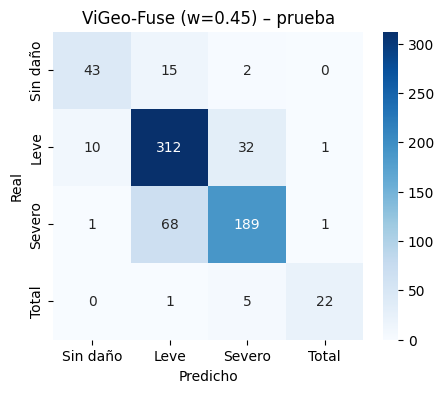

In [ ]:
p_fus_test = w_opt*p_rf_test + (1-w_opt)*p_cnn_test
pred_fus = p_fus_test.argmax(axis=1)

print(classification_report(y_test, pred_fus, target_names=NOMBRES, digits=3))
matriz(y_test, pred_fus, f'ViGeo-Fuse (w={w_opt}) – prueba')

## Paso 9 · Comparación final (conjunto de prueba)

,Exactitud (OA),F1 macro,F1 ponderado,Kappa
Modelo,,,,
CNN (solo imagen),0.7920,0.7840,0.7913,0.6496
Random Forest (solo geoespacial),0.6481,0.5960,0.6474,0.4124
ViGeo-Fuse (fusión),0.8063,0.8019,0.8048,0.6699


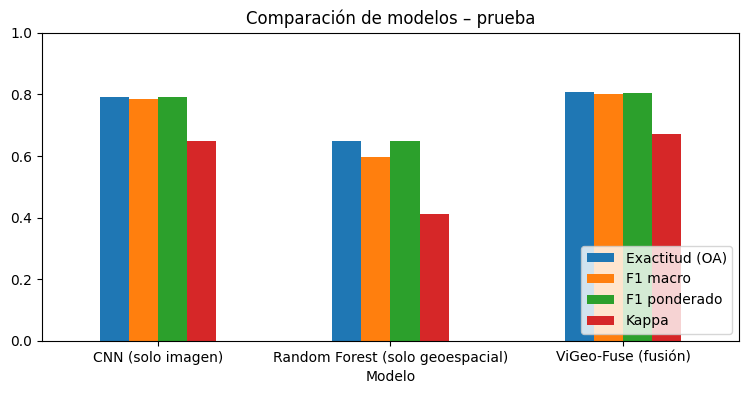

In [ ]:
resultados = pd.DataFrame([
    evaluar(y_test, pred_cnn, 'CNN (solo imagen)'),
    evaluar(y_test, pred_rf,  'Random Forest (solo geoespacial)'),
    evaluar(y_test, pred_fus, 'ViGeo-Fuse (fusión)')]).set_index('Modelo').round(4)
display(resultados)
resultados.plot(kind='bar', figsize=(9,4), ylim=(0,1), title='Comparación de modelos – prueba')
plt.xticks(rotation=0); plt.legend(loc='lower right'); plt.show()

## Paso 10 · Mapa de daño (GeoAI)
Cada punto es un edificio del conjunto de prueba, ubicado con su longitud y latitud y coloreado según el daño que predijo la fusión.

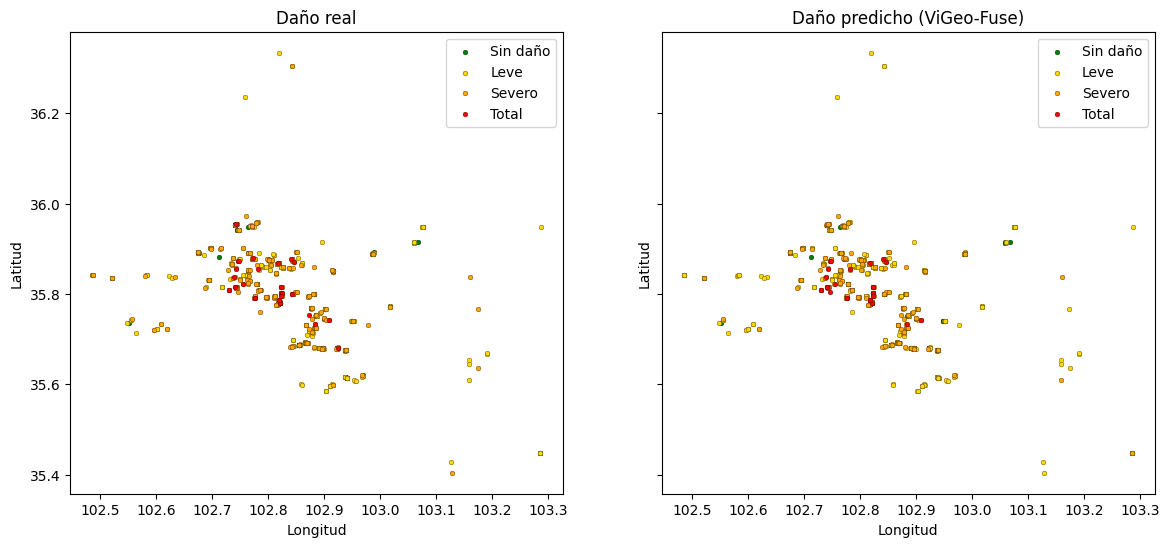

In [ ]:
colores = {0: 'green', 1: 'gold', 2: 'orange', 3: 'red'}
mapa_df = test[['Longitude', 'Latitude', 'Label']].copy()
mapa_df['Prediccion'] = pred_fus

fig, ax = plt.subplots(1, 2, figsize=(14,6), sharex=True, sharey=True)
for a, col, tit in [(ax[0], 'Label', 'Daño real'), (ax[1], 'Prediccion', 'Daño predicho (ViGeo-Fuse)')]:
    for c in range(4):
        s = mapa_df[mapa_df[col] == c]
        a.scatter(s.Longitude, s.Latitude, s=12, c=colores[c], label=NOMBRES[c], edgecolors='k', linewidths=0.2)
    a.set_title(tit); a.set_xlabel('Longitud'); a.set_ylabel('Latitud'); a.legend()
plt.show()

In [ ]:
# Mapa interactivo (puedes hacer zoom y clic en cada punto)
import folium
m = folium.Map(location=[mapa_df.Latitude.mean(), mapa_df.Longitude.mean()], zoom_start=11, tiles=None)
# Mapas base de Esri (OpenStreetMap bloquea las peticiones que vienen de Colab)
folium.TileLayer('https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
                 attr='Esri, Maxar, Earthstar Geographics', name='Satélite (Esri)').add_to(m)
folium.TileLayer('https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
                 attr='Esri', name='Calles (Esri)').add_to(m)
for _, r in mapa_df.dropna(subset=['Latitude', 'Longitude']).iterrows():
    folium.CircleMarker([r.Latitude, r.Longitude], radius=4, color=colores[int(r.Prediccion)], fill=True,
                        fill_opacity=0.8, popup=f'Real: {NOMBRES[int(r.Label)]} | Predicho: {NOMBRES[int(r.Prediccion)]}').add_to(m)
folium.LayerControl().add_to(m)
m


## Paso 11 · Guardar y descargar resultados

In [ ]:
mapa_df.to_excel('predicciones_vigeofuse.xlsx', index=False)
resultados.to_excel('metricas_vigeofuse.xlsx')
m.save('mapa_danio.html')

from google.colab import files
files.download('predicciones_vigeofuse.xlsx')
files.download('metricas_vigeofuse.xlsx')
files.download('mapa_danio.html')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Limitaciones de esta réplica (para tu informe)
- **La CNN no se reentrena:** las fotos de Jishishan no son públicas, así que se usan las probabilidades que publicaron los autores. Para reentrenarla hay que pedirles las fotos.
- **Autocorrelación espacial:** los conjuntos se dividieron al azar, así que edificios vecinos pueden quedar en entrenamiento y en prueba. Eso puede inflar el desempeño del modelo geoespacial (es la misma advertencia de Joo et al., 2026, que citas en tu revisión).
- **Un solo evento:** todo es del sismo de Jishishan 2023; no mide generalización a otros sismos.